W0000 00:00:1795447463.377579   58274 cpu_allocator_impl.cc:174] Allocation of 188160000 exceeds 10% of free system memory.
W0000 00:00:1795447463.614734   58274 cpu_allocator_impl.cc:174] Allocation of 188160000 exceeds 10% of free system memory.


Training GAN Model...
Epoch 1/5 - Generator Loss: 7.9605, Discriminator Loss: 0.1044
Epoch 2/5 - Generator Loss: 5.6932, Discriminator Loss: 0.0804
Epoch 3/5 - Generator Loss: 4.8561, Discriminator Loss: 0.2757
Epoch 4/5 - Generator Loss: 4.1015, Discriminator Loss: 0.1412
Epoch 5/5 - Generator Loss: 6.1469, Discriminator Loss: 0.1081


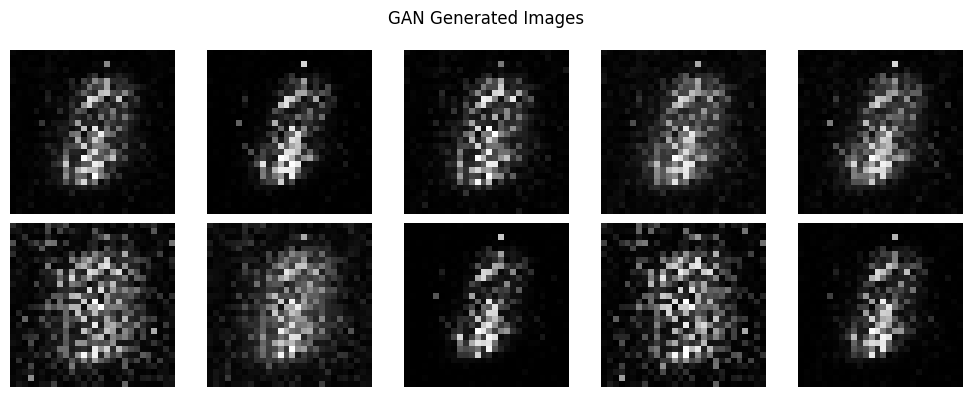


GAN Training Completed Successfully!
Generated images saved as gan_generated_images.png


In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Load MNIST dataset
(X_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

# Normalize images between -1 and 1
X_train = (X_train.astype("float32") - 127.5) / 127.5

# Flatten images
X_train = X_train.reshape(-1, 784)

# GAN parameters
noise_dim = 100
batch_size = 128
epochs = 5

# Create Generator
generator = tf.keras.Sequential([
    tf.keras.layers.Dense(256, input_dim=noise_dim),
    tf.keras.layers.LeakyReLU(negative_slope=0.2),
    tf.keras.layers.Dense(512),
    tf.keras.layers.LeakyReLU(negative_slope=0.2),
    tf.keras.layers.Dense(784, activation='tanh')
], name="Generator")

# Create Discriminator
discriminator = tf.keras.Sequential([
    tf.keras.layers.Dense(512, input_shape=(784,)),
    tf.keras.layers.LeakyReLU(negative_slope=0.2),
    tf.keras.layers.Dense(256),
    tf.keras.layers.LeakyReLU(negative_slope=0.2),
    tf.keras.layers.Dense(1)
], name="Discriminator")

# Loss function
loss_function = tf.keras.losses.BinaryCrossentropy(
    from_logits=True
)

# Optimizers
generator_optimizer = tf.keras.optimizers.Adam(0.0002)
discriminator_optimizer = tf.keras.optimizers.Adam(0.0002)

# Create dataset
dataset = tf.data.Dataset.from_tensor_slices(
    X_train
).shuffle(60000).batch(batch_size)

# Training loop
print("Training GAN Model...")

for epoch in range(epochs):

    for real_images in dataset:

        current_batch = tf.shape(real_images)[0]

        # Generate random noise
        noise = tf.random.normal(
            [current_batch, noise_dim]
        )

        # Train Discriminator
        with tf.GradientTape() as disc_tape:

            fake_images = generator(noise, training=True)

            real_output = discriminator(
                real_images, training=True
            )

            fake_output = discriminator(
                fake_images, training=True
            )

            real_loss = loss_function(
                tf.ones_like(real_output), real_output
            )

            fake_loss = loss_function(
                tf.zeros_like(fake_output), fake_output
            )

            disc_loss = real_loss + fake_loss

        disc_gradients = disc_tape.gradient(
            disc_loss, discriminator.trainable_variables
        )

        discriminator_optimizer.apply_gradients(
            zip(disc_gradients, discriminator.trainable_variables)
        )

        # Train Generator
        noise = tf.random.normal(
            [current_batch, noise_dim]
        )

        with tf.GradientTape() as gen_tape:

            generated_images = generator(
                noise, training=True
            )

            fake_output = discriminator(
                generated_images, training=False
            )

            gen_loss = loss_function(
                tf.ones_like(fake_output), fake_output
            )

        gen_gradients = gen_tape.gradient(
            gen_loss, generator.trainable_variables
        )

        generator_optimizer.apply_gradients(
            zip(gen_gradients, generator.trainable_variables)
        )

    print(
        f"Epoch {epoch + 1}/{epochs} - "
        f"Generator Loss: {gen_loss.numpy():.4f}, "
        f"Discriminator Loss: {disc_loss.numpy():.4f}"
    )

# Generate final images
noise = tf.random.normal([10, noise_dim])
generated_images = generator(noise, training=False)

# Display generated images
generated_images = (generated_images.numpy() + 1) / 2

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(
        generated_images[i].reshape(28, 28),
        cmap='gray'
    )
    plt.axis('off')

plt.suptitle("GAN Generated Images")
plt.tight_layout()

# Save generated images
plt.savefig("gan_generated_images.png")
plt.show()

print("\nGAN Training Completed Successfully!")
print("Generated images saved as gan_generated_images.png")